In [7]:
from ucimlrepo import fetch_ucirepo
 
# From archive.uci.edu to import data in Python
# fetch dataset
breast_cancer_wisconsin_prognostic = fetch_ucirepo(id=16)
 
# data (as pandas dataframes)
X = breast_cancer_wisconsin_prognostic.data.features
y = breast_cancer_wisconsin_prognostic.data.targets
 
# metadata
print(breast_cancer_wisconsin_prognostic.metadata)
 
# variable information
print(breast_cancer_wisconsin_prognostic.variables)

{'uci_id': 16, 'name': 'Breast Cancer Wisconsin (Prognostic)', 'repository_url': 'https://archive.ics.uci.edu/dataset/16/breast+cancer+wisconsin+prognostic', 'data_url': 'https://archive.ics.uci.edu/static/public/16/data.csv', 'abstract': 'Prognostic Wisconsin Breast Cancer Database', 'area': 'Health and Medicine', 'tasks': ['Classification', 'Regression'], 'characteristics': ['Multivariate'], 'num_instances': 198, 'num_features': 33, 'feature_types': ['Real'], 'demographics': [], 'target_col': ['Outcome'], 'index_col': ['ID'], 'has_missing_values': 'yes', 'missing_values_symbol': 'NaN', 'year_of_dataset_creation': 1995, 'last_updated': 'Sun Jan 14 2024', 'dataset_doi': '10.24432/C5GK50', 'creators': ['William Wolberg', 'W. Street', 'Olvi Mangasarian'], 'intro_paper': None, 'additional_info': {'summary': 'Each record represents follow-up data for one breast cancer case.  These are consecutive patients seen by Dr. Wolberg since 1984, and include only those cases exhibiting invasive brea

## External Validation — Wisconsin Prognostic (WPBC)
 
This checks whether the tuned Logistic Regression from `05_Zoom_LogReg.ipynb`, trained on the 7
features selected in `04_Feature_Selection.ipynb`, still predicts malignant on an external,
similar-but-different cohort: the Wisconsin **Prognostic** Breast Cancer dataset (WPBC, UCI id=16).
 
**Framing.** WPBC contains only patients already diagnosed with invasive breast cancer — no benign
cases. Its target (`Outcome`, R/N) is recurrence, not diagnosis. There is therefore no negative class
to compute precision, F1 or ROC-AUC against: this check can only report recall, i.e. the fraction of
these 198 known-malignant patients the model still labels malignant (`label=1`).
 
**Preprocessing alignment.** `scaler_all` was never persisted in `04_Feature_Selection.ipynb`, so it is
reconstructed here deterministically (same raw file, same `random_state`, same `split_and_scale` call)
rather than refit on WPBC — refitting a new scaler on WPBC would place its features in a different
space than the one the model's coefficients were learned in. WPBC's `1`/`2`/`3` column suffixes
(mean/SE/worst) are renamed to the Original dataset's `_mean`/`_se`/`_worst` naming before applying
the scaler and keeping the 7 selected features. The tuned model itself is not persisted either, so it
is retrained here on the exported training set, identically to `05_Zoom_LogReg.ipynb`.
 
**Ground truth.** WPBC has no diagnosis column — only `Outcome` (recurrence, R/N). Per the dataset's
own documentation, every case is already invasive breast cancer with no distant metastasis at
diagnosis: WPBC contains malignant cases only, by inclusion criterion, not by anything inferable from
its features. A `label` column is therefore created here as a constant `1` for every row, based on
that documented inclusion criterion — not derived from any feature.

In [8]:
import os
import sys
import numpy as np
import pandas as pd
from ucimlrepo import fetch_ucirepo
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import recall_score
 
sys.path.append(os.path.join("..", "01_scripts"))
from dataset import load_data, get_feature_columns
from preprocessing import split_and_scale
 
RANDOM_STATE = 42
CV_FOLDS = 10
DATA_PATH = os.path.join("..", "02_data", "raw", "10_Breast_Cancer_Wisconsin_Diagnostic.csv")
RESULTS_DIR = os.path.join("..", "04_results")
PROCESSED_DATA_DIR = os.path.join("..", "02_data", "processed")
 
# Reconstruct scaler_all (not persisted): refit on the same raw file with the same
# split, deterministic given RANDOM_STATE -- must match 04_Feature_Selection.ipynb.
df_original = load_data(DATA_PATH)
original_features = get_feature_columns(df_original)
_, _, _, _, scaler_all = split_and_scale(
    df_original, original_features, test_size=0.3, random_state=RANDOM_STATE
)
 
selected_features = pd.read_csv(os.path.join(RESULTS_DIR, "04_selected_features.csv"))["feature"].tolist()
 
# Retrain the tuned model exactly as in 05_Zoom_LogReg.ipynb (not persisted either).
train_df = pd.read_csv(os.path.join(PROCESSED_DATA_DIR, "04_train_selected_features.csv"))
X_train_sel = train_df.drop(columns=["label"]).values
y_train = train_df["label"].values
 
param_grid = {"C": np.logspace(-3, 2, 30)}
grid_logreg = GridSearchCV(
    LogisticRegression(random_state=RANDOM_STATE, max_iter=5000),
    param_grid, cv=CV_FOLDS, scoring='recall', n_jobs=-1
)
grid_logreg.fit(X_train_sel, y_train)
best_logreg = grid_logreg.best_estimator_
print(f"Retrained model: C={grid_logreg.best_params_['C']:.4f}\n")
 
# 1) Load WPBC and rename its 1/2/3 suffixes to the Original _mean/_se/_worst naming.
wpbc = fetch_ucirepo(id=16)
X_wpbc = wpbc.data.features.copy()
 
base_properties = [
    "radius", "texture", "perimeter", "area", "smoothness",
    "compactness", "concavity", "concave_points", "symmetry", "fractal_dimension",
]
suffix_map = {"1": "_mean", "2": "_se", "3": "_worst"}
rename_map = {f"{prop}{suf}": f"{prop}{suffix_map[suf]}" for prop in base_properties for suf in "123"}
X_wpbc = X_wpbc.rename(columns=rename_map)
 
missing = [f for f in original_features if f not in X_wpbc.columns]
if missing:
    raise ValueError(f"WPBC is missing expected columns after renaming: {missing}")
 
# 2) Apply the Original scaler (fit on all 30 features), then keep the 7 selected ones.
X_wpbc_scaled_full = scaler_all.transform(X_wpbc[original_features].values)
X_wpbc_scaled = pd.DataFrame(X_wpbc_scaled_full, columns=original_features)[selected_features].values
 
# 3) Ground truth: label=1 for every row, per WPBC's documented inclusion criterion
#    (invasive breast cancer only) -- not derived from any feature column.
y_true_wpbc = pd.Series(1, index=X_wpbc.index, name="label")
 
y_pred_wpbc = best_logreg.predict(X_wpbc_scaled)
y_proba_wpbc = best_logreg.predict_proba(X_wpbc_scaled)[:, 1]
 
recall_wpbc = recall_score(y_true_wpbc, y_pred_wpbc)
print(f"WPBC (n={len(y_pred_wpbc)}, all malignant by inclusion criterion): "
      f"{(y_pred_wpbc == 1).sum()}/{len(y_pred_wpbc)} predicted malignant "
      f"(recall = {recall_wpbc:.4f})")
 
missed = X_wpbc[selected_features].copy()
missed["predicted_label"] = y_pred_wpbc
missed["malignant_probability"] = y_proba_wpbc
missed = missed[missed["predicted_label"] == 0].sort_values("malignant_probability")
print(f"\n{len(missed)} patient(s) predicted benign (false negatives on this cohort):")
display(missed)

Retrained model: C=30.3920
WPBC (n=198, all malignant by inclusion criterion): 188/198 predicted malignant (recall = 0.9495)

10 patient(s) predicted benign (false negatives on this cohort):


,radius_mean,concave_points_mean,radius_se,texture_worst,smoothness_worst,concave_points_worst,symmetry_worst,predicted_label,malignant_probability
119,11.76,0.03515,0.6450,23.39,0.1137,0.07160,0.1978,0,0.002212
46,13.80,0.05069,0.2787,20.86,0.1411,0.13830,0.2589,0,0.019709
32,13.44,0.02031,0.2385,30.25,0.1094,0.11120,0.2994,0,0.039137
63,12.77,0.02704,0.2367,33.37,0.1419,0.09331,0.2829,0,0.164040
111,15.61,0.02847,0.2298,31.67,0.1084,0.08568,0.2683,0,0.232652
88,15.12,0.04079,0.2711,20.24,0.1491,0.12520,0.3415,0,0.277685
180,15.78,0.04475,0.2059,22.52,0.1386,0.12340,0.3261,0,0.297918
163,15.05,0.04335,0.3860,28.06,0.1246,0.11200,0.2282,0,0.328448
104,13.96,0.05246,0.4250,22.07,0.1512,0.13740,0.3068,0,0.428739
78,15.28,0.03263,0.2054,28.03,0.1301,0.12260,0.3175,0,0.456650


### Understanding the false negatives
 
Two complementary views explain why these patients lean "benign": where their 7 selected features
sit relative to the training distributions of benign vs. malignant Original cases, and how each
feature contributes to the model's log-odds decision (`coefficient x standardized value`), since a
Logistic Regression's decision is a direct sum of these per-feature contributions.

C:\Users\coren\AppData\Local\Temp\ipykernel_7860\3881962969.py:23: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(
C:\Users\coren\AppData\Local\Temp\ipykernel_7860\3881962969.py:23: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(
C:\Users\coren\AppData\Local\Temp\ipykernel_7860\3881962969.py:23: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(
C:\Users\coren\AppData\Local\Temp\ipykernel_7860\3881962969.py:23: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` 

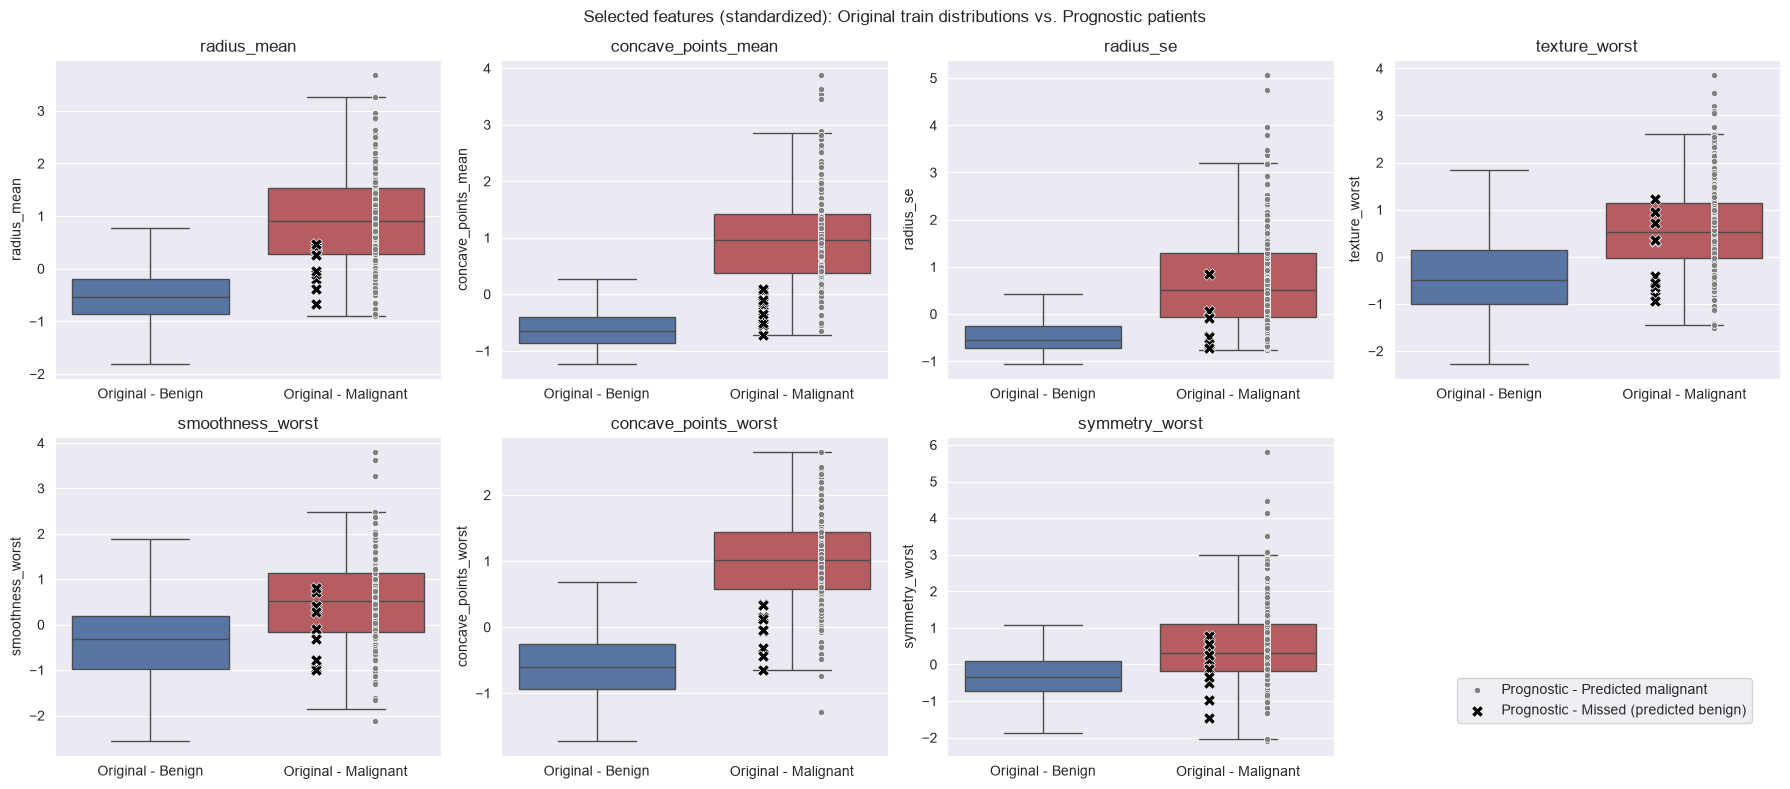

--- Mean per-feature contribution to the logistic regression log-odds ---


,Original - Malignant (train avg.),Prognostic - Predicted malignant (avg.),Prognostic - Missed (avg.)
radius_mean,4.177,4.327,0.163
concave_points_mean,0.263,0.274,-0.074
radius_se,2.117,2.180,-0.972
texture_worst,1.342,1.669,0.047
smoothness_worst,0.797,0.736,-0.080
concave_points_worst,1.544,1.553,-0.060
symmetry_worst,0.633,0.626,-0.153
intercept,-0.775,-0.775,-0.775
log-odds (sum),10.098,10.591,-1.903


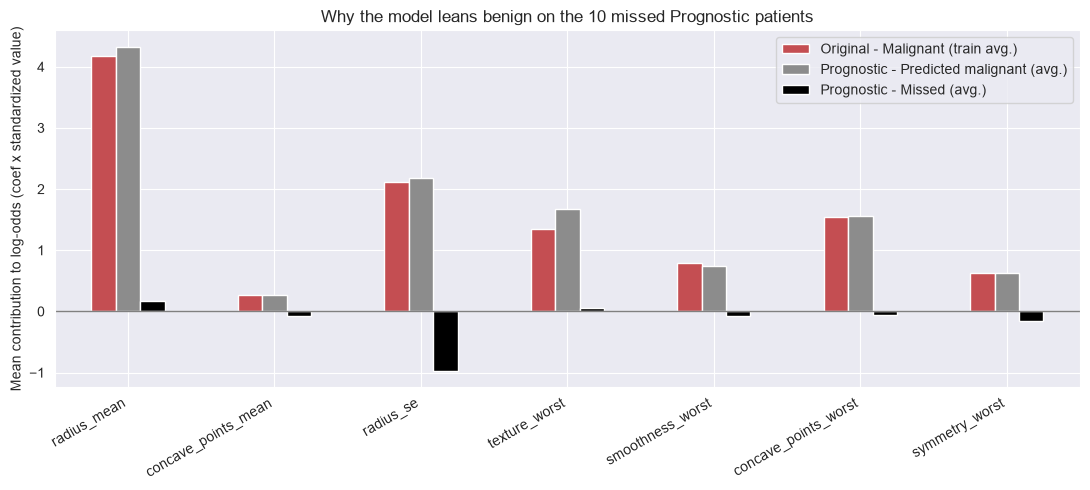

In [9]:
import seaborn as sns
import matplotlib.pyplot as plt
 
FIGURES_DIR = os.path.join("..", "05_figures")
os.makedirs(FIGURES_DIR, exist_ok=True)
 
X_wpbc_scaled_df = pd.DataFrame(
    X_wpbc_scaled_full, columns=original_features, index=X_wpbc.index
)[selected_features]
 
train_df_selected = train_df.copy()
train_df_selected["diagnosis"] = np.where(
    train_df_selected["label"] == 1, "Original - Malignant", "Original - Benign"
)
 
wpbc_status = pd.Series("Prognostic - Predicted malignant", index=X_wpbc.index)
wpbc_status.loc[missed.index] = "Prognostic - Missed (predicted benign)"
 
fig, axes = plt.subplots(2, 4, figsize=(18, 8))
axes = axes.flatten()
 
for i, (ax, feat) in enumerate(zip(axes, selected_features)):
    sns.boxplot(
        data=train_df_selected, x="diagnosis", y=feat, ax=ax,
        order=["Original - Benign", "Original - Malignant"],
        palette={"Original - Benign": "#4C72B0", "Original - Malignant": "#C44E52"},
        showfliers=False,
    )
    for status, x_pos, color, marker, size in [
        ("Prognostic - Predicted malignant", 1.15, "grey", "o", 20),
        ("Prognostic - Missed (predicted benign)", 0.85, "black", "X", 70),
    ]:
        idx = wpbc_status[wpbc_status == status].index
        ax.scatter(
            np.full(len(idx), x_pos), X_wpbc_scaled_df.loc[idx, feat],
            color=color, marker=marker, s=size, edgecolor="white", linewidth=0.5, zorder=5,
            label=status if i == 0 else None,
        )
    ax.set_title(feat)
    ax.set_xlabel("")
 
axes[-1].axis("off")
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="lower right", bbox_to_anchor=(0.98, 0.08))
fig.suptitle("Selected features (standardized): Original train distributions vs. Prognostic patients")
fig.tight_layout()
fig.savefig(os.path.join(FIGURES_DIR, "07_wpbc_feature_positions.png"))
plt.show()
 
coefs = pd.Series(best_logreg.coef_[0], index=selected_features)
intercept = best_logreg.intercept_[0]
 
 
def mean_contribution(df_scaled):
    return (df_scaled[selected_features] * coefs).mean()
 
 
contrib_original_malignant = mean_contribution(
    train_df_selected[train_df_selected["diagnosis"] == "Original - Malignant"])
contrib_wpbc_correct = mean_contribution(
    X_wpbc_scaled_df.loc[wpbc_status[wpbc_status == "Prognostic - Predicted malignant"].index])
contrib_wpbc_missed = mean_contribution(X_wpbc_scaled_df.loc[missed.index])
 
contrib_table = pd.DataFrame({
    "Original - Malignant (train avg.)": contrib_original_malignant,
    "Prognostic - Predicted malignant (avg.)": contrib_wpbc_correct,
    "Prognostic - Missed (avg.)": contrib_wpbc_missed,
})
contrib_table.loc["intercept"] = intercept
contrib_table.loc["log-odds (sum)"] = contrib_table.drop(index="intercept").sum() + intercept
 
print("--- Mean per-feature contribution to the logistic regression log-odds ---")
display(contrib_table.round(3))
 
contrib_table.drop(index=["intercept", "log-odds (sum)"]).plot(
    kind="bar", figsize=(11, 5), color=["#C44E52", "#8c8c8c", "#000000"]
)
plt.axhline(0, color="grey", linewidth=1)
plt.ylabel("Mean contribution to log-odds (coef x standardized value)")
plt.title("Why the model leans benign on the 10 missed Prognostic patients")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.savefig(os.path.join(FIGURES_DIR, "07_wpbc_logodds_contribution.png"))
plt.show()

**Findings.** All 7 features contribute positively to the average log-odds of the Original training
malignant cases (summing to 10.098) and of the Prognostic patients correctly predicted malignant
(10.591), but collapse for the 10 missed patients, whose average log-odds is -1.903 — well below the 0
decision threshold. No single feature explains this alone: `radius_mean` (4.177 -> 0.163) and
`radius_se` (2.117 -> -0.972) show by far the largest drops, followed by `concave_points_worst`
(1.544 -> -0.060) and `texture_worst` (1.342 -> 0.047); `concave_points_mean`, `smoothness_worst` and
`symmetry_worst` also turn slightly negative. The boxplots confirm this: on nearly every feature, the
missed patients sit inside or near the benign range rather than standing out as an outlier on one
specific measurement. This is a systematic, whole-profile shift rather than a single failure mode —
these 10 patients present smaller, smoother, less irregular nuclei across essentially every selected
feature, resembling the benign training profile despite being malignant by inclusion criterion,
plausibly corresponding to smaller or less advanced tumors that this 7-feature profile, tuned on the
Original cohort's benign/malignant contrast, does not fully capture.

### Spectral Clustering — do Prognostic patients cluster with the malignant group?
 
The log-odds decomposition above suggests the 10 missed Prognostic patients resemble the Original
cohort's benign profile on the 7 selected features. This is checked here without using any label or
model prediction as an input to the clustering itself: Spectral Clustering is applied to the Original
training points and the Prognostic points together, in the same standardized space (`scaler_all`, as
above), using the affinity retained as robust in `06_Zoom_Spectral.ipynb` (k-NN, `n_neighbors=10`,
`assign_labels='kmeans'`, `n_clusters=2`). Cluster membership is then compared to each point's origin —
Original benign, Original malignant, Prognostic predicted malignant, or Prognostic missed — to see
whether the missed patients land in the same cluster as the Original benign cases.

--- Cluster membership by origin group ---


cluster,0,1
origin,,
Original - Benign,4,246
Original - Malignant,131,17
Prognostic - Missed (predicted benign),0,10
Prognostic - Predicted malignant,175,13


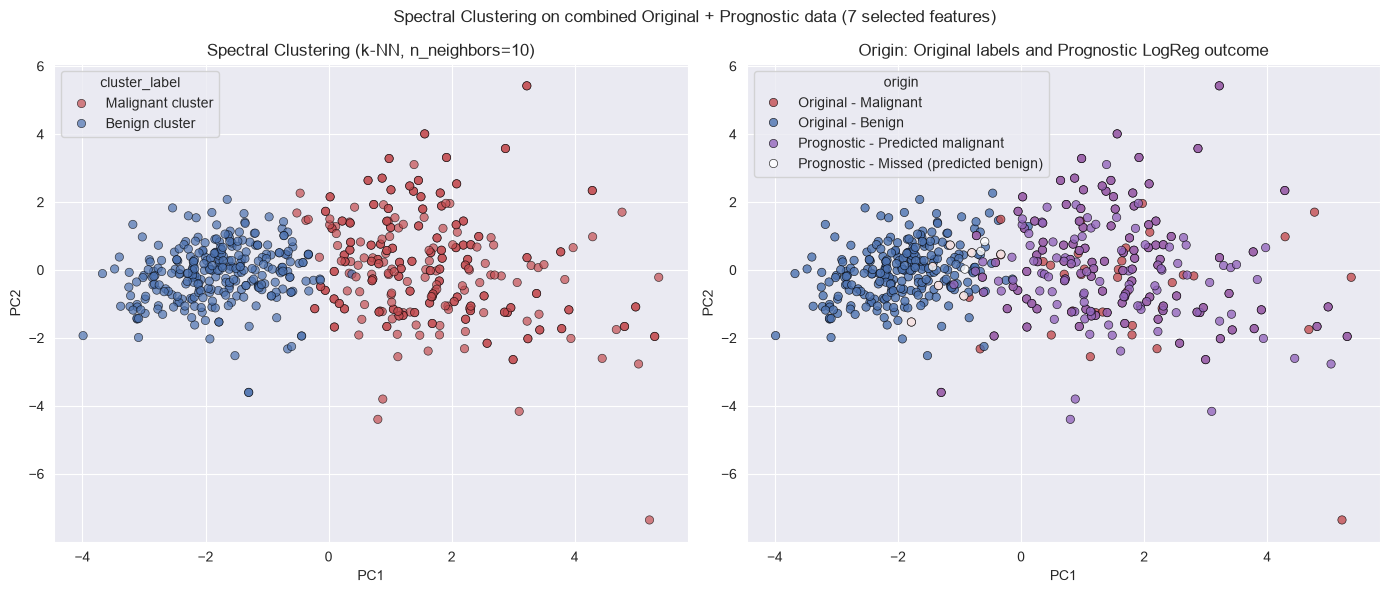

In [10]:
from sklearn.cluster import SpectralClustering
from sklearn.decomposition import PCA
import seaborn as sns
 
original_points = train_df_selected[selected_features].copy()
original_points["origin"] = train_df_selected["diagnosis"]
 
wpbc_points = X_wpbc_scaled_df.copy()
wpbc_points["origin"] = wpbc_status
 
combined = pd.concat([original_points, wpbc_points], ignore_index=True)
X_combined = combined[selected_features].values
 
spectral_wpbc = SpectralClustering(
    n_clusters=2, affinity="nearest_neighbors", n_neighbors=10,
    assign_labels="kmeans", random_state=RANDOM_STATE
)
combined["cluster"] = spectral_wpbc.fit_predict(X_combined)
 
cluster_by_origin = pd.crosstab(combined["origin"], combined["cluster"])
cluster_by_origin.to_csv(os.path.join(RESULTS_DIR, "07_wpbc_spectral_crosstab.csv"))
print("--- Cluster membership by origin group ---")
display(cluster_by_origin)
 
# Cluster indices are arbitrary (0/1 assigned by sklearn), so the "benign" and
# "malignant" cluster are identified from the crosstab rather than hardcoded.
malignant_cluster = cluster_by_origin.loc["Original - Malignant"].idxmax()
benign_cluster = cluster_by_origin.loc["Original - Benign"].idxmax()
combined["cluster_label"] = combined["cluster"].map({
    malignant_cluster: "Malignant cluster", benign_cluster: "Benign cluster"
})
 
X_pca_combined = PCA(n_components=2, random_state=RANDOM_STATE).fit_transform(X_combined)
 
fig, axes = plt.subplots(1, 2, figsize=(14, 6))
sns.scatterplot(x=X_pca_combined[:, 0], y=X_pca_combined[:, 1], hue=combined["cluster_label"],
                 palette={"Benign cluster": "#4C72B0", "Malignant cluster": "#C44E52"},
                 ax=axes[0], alpha=0.7, edgecolor="k")
axes[0].set_title("Spectral Clustering (k-NN, n_neighbors=10)")
axes[0].set_xlabel("PC1")
axes[0].set_ylabel("PC2")
 
origin_palette = {
    "Original - Benign": "#4C72B0",
    "Original - Malignant": "#C44E52",
    "Prognostic - Predicted malignant": "#9467BD",
    "Prognostic - Missed (predicted benign)": "#FFFFFF",
}
sns.scatterplot(x=X_pca_combined[:, 0], y=X_pca_combined[:, 1], hue=combined["origin"],
                 palette=origin_palette, ax=axes[1], alpha=0.8, edgecolor="k")
axes[1].set_title("Origin: Original labels and Prognostic LogReg outcome")
axes[1].set_xlabel("PC1")
axes[1].set_ylabel("PC2")
 
fig.suptitle("Spectral Clustering on combined Original + Prognostic data (7 selected features)")
fig.tight_layout()
fig.savefig(os.path.join(FIGURES_DIR, "07_wpbc_spectral_clusters.png"))
plt.show()

**Findings.** The two clusters align closely with the diagnostic labels: the benign cluster contains
246 of 263 diagnostic benign points (93.5%), and the malignant cluster contains 131 of 148 diagnostic
malignant points (88.5%). All 10 WPBC patients missed by the Logistic Regression fall in the benign
cluster (10/10), while the 188 correctly predicted malignant patients fall overwhelmingly in the
malignant cluster (175/188, 93%). This is an independent, fully label-free confirmation of the log-odds
finding above: the 10 missed patients are not scattered noise but sit squarely within the same natural
group as the diagnostic benign cases, using a method that never saw the diagnosis or the model's
decision boundary.

## Discussion
 
The Logistic Regression trained on the 7 features selected from the Original cohort generalizes well
to the Prognostic dataset (WPBC), an external cohort never used for feature selection or training: it
correctly flags 188 of 198 patients as malignant (recall = 0.9495), despite WPBC being a different
clinical context (invasive, non-metastatic follow-up cases rather than a benign/malignant diagnostic
split).
 
The 10 missed patients are not random noise: the log-odds decomposition shows a systematic drop across
all 7 selected features rather than a single outlier feature, indicating a genuinely different
(smaller, smoother, less irregular) morphological profile — closer to the Original cohort's benign
range than its malignant one. This is plausible given the Prognostic dataset's inclusion criterion
allows a wider range of tumor sizes and stages than the binary contrast the original feature selection
was tuned on.
 
An unsupervised check reinforces this conclusion. Spectral Clustering, run on the combined Original
and Prognostic points with no label or model output as input, recovers two clusters that align closely
with the Original benign/malignant split (93.5% and 88.5% purity respectively). All 10 Prognostic
patients missed by the Logistic Regression fall in the cluster dominated by Original benign cases,
while the 188 correctly predicted malignant patients fall overwhelmingly (93%) in the
malignant-dominated cluster. Two independent methods — one supervised (log-odds decomposition), one
entirely unsupervised (Spectral Clustering) — converge on the same conclusion: these 10 patients share
a genuine morphological resemblance to benign tissue on the 7 selected features, rather than this
being an artifact specific to the Logistic Regression's decision boundary.
 
**Limitations.**
- This is a recall-only check: the Prognostic dataset has no benign cases, so it cannot assess whether
  the model would also over-predict malignant in this population (no way to estimate precision or a
  full confusion matrix here).
- The clustering itself is not perfect (17 of 148 Original malignant points fall in the benign
  cluster, and 4 of 263 Original benign points fall in the malignant cluster), so it corroborates the
  log-odds finding rather than independently proving it.
- The scaler and model were reconstructed rather than loaded from disk, since neither `scaler_all` nor
  the tuned Logistic Regression was persisted upstream; exact reproducibility relies on
  `split_and_scale` being fully deterministic given `random_state`.
- Only the 7 selected features are reused here; whether they (or a model retrained on the Prognostic
  dataset's own recurrence target) predict recurrence is a separate question this notebook does not
  address.
 